## documentation

### Exploring the structure of `plotsTopEFT.pkl.gz`

The output file produced by `run_analysis.py` is a compressed pickle containing a Python dictionary:

```text
plotsTopEFT.pkl.gz
└── data (dict)
    ├── invmass
    ├── invmass_sumw2
    ├── njets
    ├── njets_sumw2
    └── ...
```

The dictionary contains **20 `HistEFT` objects**, corresponding to **10 physical observables** and their associated `_sumw2` histograms:

```text
observable
observable_sumw2
```

Examples:

```text
invmass          / invmass_sumw2
njets            / njets_sumw2
l0conept         / l0conept_sumw2
...
```

The `_sumw2` histograms store the **sum of squared event weights (Σw²)** and are used for statistical uncertainty calculations. They are **not related to EFT quadratic terms**.

---

### Internal structure of a HistEFT object

Each observable (e.g. `data["invmass"]`) is stored as a `HistEFT` object with the following axes:

```text
process
channel
systematic
physical variable
quadratic_term
```

For example:

```text
HistEFT("invmass")
├── process
├── channel
├── systematic
├── invmass
└── quadratic_term
```

#### process

Identifies the dataset or physics sample:

```text
ttHnobb_central2023
TTTT_central2023
DYJetsToLL_MLL-50_central2023
data2023
nonprompt2023
...
```

#### channel

Defines the analysis region/category:

```text
2lss_ee_CR_1j
2lss_em_CR_2j
3l_eee_CR_0j
1l_e_1tau_CR_3j
...
```

For example:

```text
2lss_ee_CR_1j
= 2 same-sign leptons
= electron-electron channel
= control region
= 1 jet category
```

#### systematic

Contains systematic variations.

In this file:

```python
["nominal"]
```

so only nominal yields are stored.

#### physical variable

The actual observable being histogrammed.

Example:

```python
Regular(40, 60, 140, name="invmass")
```

corresponds to:

```text
40 bins between 60 and 140 GeV
```

representing the dilepton invariant mass distribution.

#### quadratic_term

Stores the EFT coefficient dimension.

For the current file:

```
Integer(0,1,name="quadratic_term")
```

and

```python
h.wc_names == []
```

meaning that only one coefficient is present:

```text
SM × SM
```

Therefore this particular file is effectively **SM-only**, even though it uses the `HistEFT` class.

---




### Where are the actual histogram contents?

The histogram values are accessed through:

```python
h.view(flow=True)
```

This returns a dictionary whose keys are combinations of:

```text
(process, channel, systematic)
```

and whose values are arrays containing the histogram bin contents.

Example:

```python
raw = h.view(flow=True)

first_key = next(iter(raw))
print(first_key)
print(raw[first_key])
```

A typical key looks like:

```text
process='TWZ_Tto2Q_WtoLNu_Zto2L_central2023BPix'
channel='2lss_ee_CR_1j'
systematic='nominal'
```

and the corresponding value contains the binned data.

For the `invmass` histogram the array shape is expected to be:

```text
(n_bins + flow bins, n_quadratic_terms)
```

For this file:

```text
(42, 1)
```

corresponding to:

```text
40 physical bins
+ 1 underflow bin
+ 1 overflow bin
```

and a single EFT coefficient (`SM × SM`).

---

### Conceptual picture

A `HistEFT` object is not a single histogram. It is a collection of histograms indexed by:

```text
process × channel × systematic
```

For example:

```text
data["invmass"]
├── process=A, channel=X, systematic=nominal
├── process=A, channel=Y, systematic=nominal
├── process=B, channel=X, systematic=nominal
├── process=B, channel=Y, systematic=nominal
└── ...
```

Each combination stores its own binned distribution of the physical observable.

---

### Main takeaway

The current file contains **20 HistEFT objects** (10 observables + 10 statistical uncertainty histograms). Each `HistEFT` is organized through the axes:

```text
process
channel
systematic
physical variable
quadratic_term
```

while the actual histogram contents are stored in the arrays returned by:

```python
h.view(flow=True)
```

In this particular file, `wc_names = []`, so the `quadratic_term` axis contains only the Standard Model contribution (`SM × SM`). The next step is to inspect a histogram with non-empty `wc_names` to understand how EFT coefficients are stored and later reproduce that behavior using `hist.Hist`.


In [42]:
import sys
print(sys.version)

3.11.15 | packaged by conda-forge | (main, Jun 11 2026, 03:34:02) [GCC 14.3.0]


## open both pkl files

In [ ]:
import gzip
import pickle

with gzip.open("/users/ldiazlie/topeft/analysis/topeft_run2/histos/plotsTopEFT_standard_after.pkl.gz", "rb") as f:
    data_std = pickle.load(f)

print(type(data_std))
print(data_std.keys())

h_standard = data_std["njets"]
print(type(h_standard))

: 

In [ ]:
print(h_standard._use_multicell)
k = next(iter(h_standard._dense_hists))
print(h_standard._dense_hists[k].storage_type)
h_standard.axes 

: 

In [9]:
with gzip.open("/users/ldiazlie/topeft/analysis/topeft_run2/histos/plotsTopEFT_multicell.pkl.gz", "rb") as f:
    data_mul = pickle.load(f)

print(type(data_mul))
print(data_mul.keys())

h_multicell = data_mul["njets"]
print(type(h_multicell))

<class 'dict'>
dict_keys(['npvs', 'npvs_sumw2', 'npvsGood', 'npvsGood_sumw2', 'invmass', 'invmass_sumw2', 'ptbl', 'ptbl_sumw2', 'ptz', 'ptz_sumw2', 'njets', 'njets_sumw2', 'nbtagsl', 'nbtagsl_sumw2', 'nbtagsm', 'nbtagsm_sumw2', 'l0pt', 'l0pt_sumw2', 'l0ptcorr', 'l0ptcorr_sumw2', 'l0conept', 'l0conept_sumw2', 'l0eta', 'l0eta_sumw2', 'l1pt', 'l1pt_sumw2', 'l1ptcorr', 'l1ptcorr_sumw2', 'l1conept', 'l1conept_sumw2', 'l1eta', 'l1eta_sumw2', 'j0pt', 'j0pt_sumw2', 'fwd0pt', 'fwd0pt_sumw2', 'b0pt', 'b0pt_sumw2', 'j0eta', 'j0eta_sumw2', 'fwd0eta', 'fwd0eta_sumw2', 'ht', 'ht_sumw2', 'met', 'met_sumw2', 'ljptsum', 'ljptsum_sumw2', 'o0pt', 'o0pt_sumw2', 'bl0pt', 'bl0pt_sumw2', 'lj0pt', 'lj0pt_sumw2', 'ptz_wtau', 'ptz_wtau_sumw2', 'tau0Tpt', 'tau0Tpt_sumw2', 'tau0Fpt', 'tau0Fpt_sumw2', 'lt', 'lt_sumw2', 'l0_gen_pdgId', 'l0_gen_pdgId_sumw2', 'l1_gen_pdgId', 'l1_gen_pdgId_sumw2', 'l2_gen_pdgId', 'l2_gen_pdgId_sumw2', 'l0_genParent_pdgId', 'l0_genParent_pdgId_sumw2', 'l1_genParent_pdgId', 'l1_genParen

In [10]:
print(h_multicell._use_multicell)
k = next(iter(h_multicell._dense_hists))
print(h_multicell._dense_hists[k].storage_type)
h_multicell.axes #plotTopEFT_multicell.pkl.gz

True
<class 'boost_histogram.storage.MultiCell'>


(StrCategory(['ttHJet_privateUL17'], growth=True, name='process'),
 StrCategory(['2lss_p', '2lss_m', '2lss_4t_p', '2lss_4t_m', '3l_onZ_1b', '3l_onZ_2b', '3l_m_offZ_1b', '3l_m_offZ_2b', '3l_p_offZ_1b', '3l_p_offZ_2b', '4l', '2lss_CR', '2lss_CRflip', '2los_CRZ', '2los_CRtt', '3l_CR'], growth=True, name='channel'),
 StrCategory(['nominal'], growth=True, name='systematic', label='Systematic Uncertainty'),
 StrCategory(['isSR_2lSS', 'isAR_2lSS', 'isSR_3l', 'isAR_3l', 'isSR_4l', 'isSR_2lOS', 'isAR_2lOS'], growth=True, name='appl', label='AR/SR'),
 Regular(7, 0, 7, name='njets', label='Jet multiplicity '))

In [18]:
h_mul_sum = data_mul["njets_sumw2"]
print(h_mul_sum._use_multicell)
k = next(iter(h_mul_sum._dense_hists))
print(h_mul_sum._dense_hists[k].storage_type)
h_mul_sum.axes


True
<class 'boost_histogram.storage.MultiCell'>


(StrCategory(['ttHJet_privateUL17'], growth=True, name='process'),
 StrCategory(['2lss_p', '2lss_m', '2lss_4t_p', '2lss_4t_m', '3l_onZ_1b', '3l_onZ_2b', '3l_m_offZ_1b', '3l_m_offZ_2b', '3l_p_offZ_1b', '3l_p_offZ_2b', '4l', '2lss_CR', '2lss_CRflip', '2los_CRZ', '2los_CRtt', '3l_CR'], growth=True, name='channel'),
 StrCategory(['nominal'], growth=True, name='systematic', label='Systematic Uncertainty'),
 StrCategory(['isSR_2lSS', 'isAR_2lSS', 'isSR_3l', 'isAR_3l', 'isSR_4l', 'isSR_2lOS', 'isAR_2lOS'], growth=True, name='appl', label='AR/SR'),
 Regular(7, 0, 7, name='njets_sumw2', label='Jet multiplicity  sum of w^2'))

In [19]:
h_std_sum = data_std["njets_sumw2"]
print(h_std_sum._use_multicell)
k = next(iter(h_std_sum._dense_hists))
print(h_std_sum._dense_hists[k].storage_type)
h_std_sum.axes

False
<class 'boost_histogram.storage.Double'>


(StrCategory(['ttHJet_privateUL17'], growth=True, name='process'),
 StrCategory(['2lss_p', '2lss_m', '2lss_4t_p', '2lss_4t_m', '3l_onZ_1b', '3l_onZ_2b', '3l_m_offZ_1b', '3l_m_offZ_2b', '3l_p_offZ_1b', '3l_p_offZ_2b', '4l', '2lss_CR', '2lss_CRflip', '2los_CRZ', '2los_CRtt', '3l_CR'], growth=True, name='channel'),
 StrCategory(['nominal'], growth=True, name='systematic', label='Systematic Uncertainty'),
 StrCategory(['isSR_2lSS', 'isAR_2lSS', 'isSR_3l', 'isAR_3l', 'isSR_4l', 'isSR_2lOS', 'isAR_2lOS'], growth=True, name='appl', label='AR/SR'),
 Regular(7, 0, 7, name='njets_sumw2', label='Jet multiplicity  sum of w^2'),
 Integer(0, 276, name='quadratic_term'))

In [22]:
h_mul_sum.wc_names

['cpt',
 'ctp',
 'cptb',
 'cQlMi',
 'cQq81',
 'cQq11',
 'cQl3i',
 'ctq8',
 'ctlTi',
 'ctq1',
 'ctli',
 'cQq13',
 'cbW',
 'cpQM',
 'cpQ3',
 'ctei',
 'cQei',
 'ctW',
 'ctlSi',
 'cQq83',
 'ctZ',
 'ctG']

## eval comparison

In [ ]:
wc_points = [
    {},  # SM
    {"ctG": 1.0},
    {"ctG": -1.0},
    {"ctp": 1.0},
    {"ctG": 0.5, "ctp": -0.7},
]

h_standard.eval(wc_points)


KeyboardInterrupt



: 

In [ ]:
h_standard.eval({})

In [30]:
h = data["njets"]

raw = h.view(flow=True)

for key, values in list(raw.items())[:3]:
    print("="*80)
    print(key)
    print("shape:", values.shape)
    print(values)

SparseHistTuple140187245615760(process='ttHJet_privateUL17', channel='2lss_p', systematic='nominal', appl='isSR_2lSS')
shape: (276, 9)
[[ 0.00000000e+00  0.00000000e+00  0.00000000e+00 ...  7.47601846e+00
   4.47795784e+00  2.67670225e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00 ...  4.27919568e-03
   4.63521396e-03  1.56979686e-03]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00 ...  5.06048329e-03
   1.50956268e-03  1.10981515e-03]
 ...
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00 ...  1.65288948e-01
   8.56739155e-02 -4.21505427e-02]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00 ... -2.18314975e-02
  -2.04396581e-02 -7.95970321e-02]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00 ...  5.09836750e+00
   9.37771572e+00  9.67515819e+00]]
SparseHistTuple140187245615760(process='ttHJet_privateUL17', channel='2lss_m', systematic='nominal', appl='isSR_2lSS')
shape: (276, 9)
[[ 0.00000000e+00  0.00000000e+00  0.00000000e+00 ...  7.67832873e+00
   3.55664846e+00  3.029

In [8]:
for key, values in list(raw.items())[:3]:
    print(key)
    print(values[1:-1, 0])

SparseHistTuple140187515933616(process='ttHJet_privateUL17', channel='2lss_p', systematic='nominal', appl='isSR_2lSS')
[0. 0. 0. 0. 0. 0. 0.]
SparseHistTuple140187515933616(process='ttHJet_privateUL17', channel='2lss_m', systematic='nominal', appl='isSR_2lSS')
[0. 0. 0. 0. 0. 0. 0.]
SparseHistTuple140187515933616(process='ttHJet_privateUL17', channel='2lss_4t_p', systematic='nominal', appl='isSR_2lSS')
[0. 0. 0. 0. 0. 0. 0.]


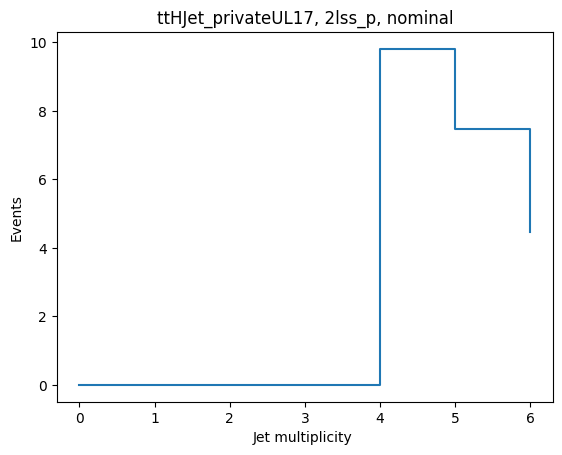

In [31]:
import gzip
import pickle
import matplotlib.pyplot as plt

## njets histEFT
h = data["njets"]

## Select a specific process, channel, and systematic
process = "ttHJet_privateUL17"
channel = "2lss_p"
systematic = "nominal"


h_sel = (
    h
    .integrate("process", process)
    .integrate("channel", channel)
    .integrate("systematic", systematic)
)


## Evaluate the quadratic function to get the histogram values. All WCs are set to zero.
vals = h_sel.eval({}) ## Other options: h_sel.eval({"ctq1": 1, "ctq2": 1, ...})
key = next(iter(vals)) # Get the first (and only) key from the evaluated histogram
y = vals[key][1:-1] # remove underflow and overflow bins

edges = h.axes["njets"].edges

plt.step(edges[:-1], y, where="post")
plt.xlabel(h.axes["njets"].label)
plt.ylabel("Events")
plt.title(f"{process}, {channel}, {systematic}")
plt.show()

## NEW PKL FILE WITH WCs

In [32]:
import sys
import hist
import boost_histogram as bh
import coffea
import awkward as ak
import correctionlib
import topcoffea
import topeft

print("Python          :", sys.version)
print("numpy           :", __import__("numpy").__version__)
print("awkward         :", ak.__version__)
print("coffea          :", coffea.__version__)
print("hist            :", hist.__version__)
print("boost-histogram :", bh.__version__)
print("correctionlib   :", correctionlib.__version__)
print("topcoffea       :", topcoffea.__file__)
print("topeft          :", topeft.__file__)

print("\nMultiCell support")
print("hist.storage.MultiCell :", hasattr(hist.storage, "MultiCell"))
print("bh.storage.MultiCell   :", hasattr(bh.storage, "MultiCell"))

Python          : 3.11.15 | packaged by conda-forge | (main, Jun 11 2026, 03:34:02) [GCC 14.3.0]
numpy           : 1.23.5
awkward         : 1.10.3
coffea          : 0.7.21
hist            : 2.10.1
boost-histogram : 1.7.2
correctionlib   : 2.7.0
topcoffea       : /users/ldiazlie/topeft/external/topcoffea/topcoffea/__init__.py
topeft          : /users/ldiazlie/topeft/topeft/__init__.py

MultiCell support
hist.storage.MultiCell : True
bh.storage.MultiCell   : True


In [33]:
import gzip
import pickle

with gzip.open("/tmp/cl007ac_histeft_demo/2023SRs_CL007AC_single_ttH_2023_njets_coffea_multicell_env_py311.pkl.gz", "rb") as f:
    data = pickle.load(f)

print(type(data))
print(data.keys())

<class 'dict'>
dict_keys(['njets', 'njets_sumw2'])


In [35]:
h = data["njets"]
h.axes

(StrCategory(['ttH_private2023'], growth=True, name='process'),
 StrCategory(['2lss_p', '2lss_m', '2lss_4t_p', '2lss_4t_m', '2lss_fwd_p', '2lss_fwd_m'], growth=True, name='channel'),
 StrCategory(['nominal', 'lepSF_muonUp', 'lepSF_muonDown', 'lepSF_elecUp', 'lepSF_elecDown', 'btagSFbc_2023Up', 'btagSFbc_2023Down', 'btagSFbc_corrUp', 'btagSFbc_corrDown', 'btagSFlight_2023Up', 'btagSFlight_2023Down', 'btagSFlight_corrUp', 'btagSFlight_corrDown', 'PUUp', 'PUDown', 'PreFiringUp', 'PreFiringDown', 'triggerSF_2023Up', 'triggerSF_2023Down', 'FSRUp', 'FSRDown', 'ISRUp', 'ISRDown', 'renormUp', 'renormDown', 'factUp', 'factDown', 'lepSF_taus_realUp', 'lepSF_taus_realDown', 'lepSF_taus_fakeUp', 'lepSF_taus_fakeDown', 'FFUp', 'FFDown', 'FFptUp', 'FFptDown', 'FFetaUp', 'FFetaDown', 'FFcloseEl_2023Up', 'FFcloseEl_2023Down', 'FFcloseMu_2023Up', 'FFcloseMu_2023Down', 'JER_2023Up', 'JER_2023Down', 'JES_Regrouped_Absolute_2023Up', 'JES_Regrouped_Absolute_2023Down', 'JES_Regrouped_AbsoluteUp', 'JES_Regro

We can see in the last line that we have 561 quadratic terms. Then, using the formula 

$$n_{quad-terms} = \frac{(n_{wc} +1 )(n_{wc} +2 )}{2}$$

we get: n_wc = 32 

Then, we have 32 wilson coefficients.

## Histogram jerarchy

```text
HistEFT("njets")
├── process
│   └── ttH_private2023
├── channel
│   ├── 2lss_p
│   ├── 2lss_m
│   ├── 2lss_4t_p
│   ├── 2lss_4t_m
│   ├── 2lss_fwd_p
│   └── 2lss_fwd_m
├── systematic
│   ├── nominal
│   ├── lepSF_muonUp
│   ├── lepSF_muonDown
│   ├── ...
│   └── FESDown
├── appl
│   ├── isSR_2lSS
│   └── isAR_2lSS
├── njets
│   └── 7 bins from 0 to 7
└── quadratic_term
    └── 561 EFT coefficients
```

---

## What does it mean?

We have different combinations: 

```text
process × channel × systematic × appl × njets bin
```

It's not just a number.

It's a vector with the quadratic coefficients:

```text
[
  SM*SM,
  WC1*SM,
  WC1*WC1,
  WC2*SM,
  WC2*WC1,
  WC2*WC2,
  ...
]
```

It means: 

```text
Each njets bin has a quadratic equation with 32 WCs.
```

and we have 561 quadratic terms.

In [13]:
print(h.wc_names)
print(len(h.wc_names))
print(h._quad_count)

['cQu8', 'ctu8', 'cQu1', 'ctd8', 'cQlMi', 'cpQ3', 'ctlTi', 'ctG', 'ctZ', 'ctW', 'ctli', 'ctb8', 'cbW', 'cQl3i', 'cQq13', 'cptb', 'ctp', 'ctei', 'cpQM', 'ctlSi', 'cQq83', 'cQq81', 'ctq1', 'ctu1', 'cQei', 'cQb8', 'cpt', 'ctq8', 'cQd1', 'cQq11', 'cQd8', 'ctd1']
32
561


In [14]:
import numpy as np

raw = h.view(flow=True)
sm = h.eval({})

first_key = next(iter(raw))

print(raw[first_key].shape)
print(sm[first_key].shape)


np.allclose(raw[first_key][:, 1], sm[first_key])

(9, 563)
(9,)


True

In [15]:
h.wc_names

['cQu8',
 'ctu8',
 'cQu1',
 'ctd8',
 'cQlMi',
 'cpQ3',
 'ctlTi',
 'ctG',
 'ctZ',
 'ctW',
 'ctli',
 'ctb8',
 'cbW',
 'cQl3i',
 'cQq13',
 'cptb',
 'ctp',
 'ctei',
 'cpQM',
 'ctlSi',
 'cQq83',
 'cQq81',
 'ctq1',
 'ctu1',
 'cQei',
 'cQb8',
 'cpt',
 'ctq8',
 'cQd1',
 'cQq11',
 'cQd8',
 'ctd1']

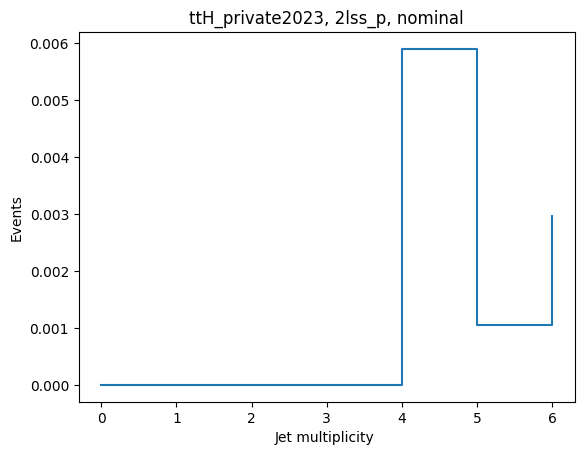

In [16]:

## Select a specific process, channel, and systematic
process = "ttH_private2023"
channel = "2lss_p"
systematic = "nominal"


h_sel = (
    h
    .integrate("process", process)
    .integrate("channel", channel)
    .integrate("systematic", systematic)
)


## Evaluate the quadratic function to get the histogram values
vals = h_sel.eval({})

key = next(iter(vals)) # Get the first (and only) key from the evaluated histogram
y = vals[key][1:-1] # remove underflow and overflow bins

edges = h.axes["njets"].edges

plt.step(edges[:-1], y, where="post")
plt.xlabel(h.axes["njets"].label)
plt.ylabel("Events")
plt.title(f"{process}, {channel}, {systematic}")
plt.show()

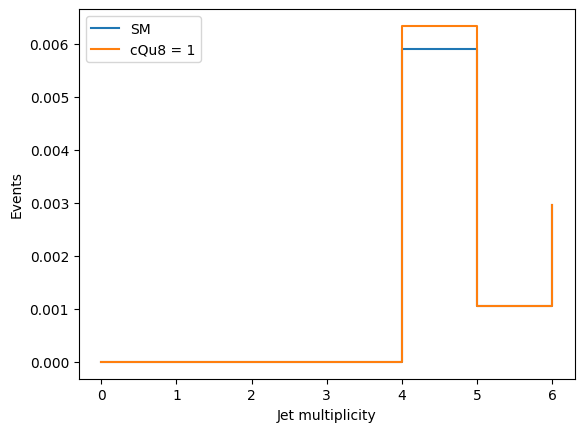

In [17]:
import numpy as np
import matplotlib.pyplot as plt

edges = h.axes["njets"].edges

sm_dict = h_sel.eval({})
eft_dict = h_sel.eval({"cQu8": 1})

key = next(iter(sm_dict))

sm = sm_dict[key][1:-1]
eft = eft_dict[key][1:-1]

plt.step(edges[:-1], sm, where="post", label="SM")
plt.step(edges[:-1], eft, where="post", label="cQu8 = 1")
plt.xlabel("Jet multiplicity")
plt.ylabel("Events")
plt.legend()
plt.show()

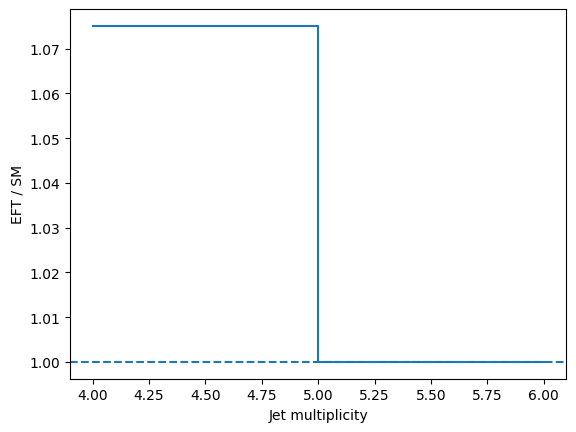

In [18]:
ratio = np.divide(
    eft,
    sm,
    out=np.full_like(eft, np.nan),
    where=sm != 0,
)

plt.step(edges[:-1], ratio, where="post")
plt.axhline(1.0, linestyle="--")
plt.xlabel("Jet multiplicity")
plt.ylabel("EFT / SM")
plt.show()

In [19]:
print("n_wc =", len(h.wc_names))
print("quad_count =", h._quad_count)


n_wc = 32
quad_count = 561


In [20]:
for key in sm_dict:
    print(key)
    print("SM sum:", np.sum(sm_dict[key][1:-1]))
    print("EFT sum:", np.sum(eft_dict[key][1:-1]))

SparseHistTuple140187282958336(appl='isSR_2lSS')
SM sum: 0.009908204565360354
EFT sum: 0.010350853839725845
SparseHistTuple140187282958336(appl='isAR_2lSS')
SM sum: 0.00015776374546740956
EFT sum: 0.00015776374546729185


### HistEFT with multicell: superficial prototype 

In [21]:
import gzip
import pickle
import numpy as np
import hist
from hist import Hist

# Select one category
h_sel = (
    h
    .integrate("process", "ttH_private2023")
    .integrate("channel", "2lss_p")
    .integrate("systematic", "nominal")
    .integrate("appl", "isSR_2lSS")
)

raw_dict = h_sel.view(flow=True)
key = next(iter(raw_dict))
raw_old = raw_dict[key]

print("Old raw shape:", raw_old.shape)
print("Expected: (njets bins + flow, quadratic terms)")

# Get njets axis info
njets_axis = h.axes["njets"]
edges = njets_axis.edges
n_quad_terms = raw_old.shape[1]

# Build equivalent MultiCell histogram
h_multi = Hist(
    hist.axis.Regular(
        len(edges) - 1,
        edges[0],
        edges[-1],
        name="njets",
        label=njets_axis.label,
        underflow=True,
        overflow=True,
    ),
    storage=hist.storage.MultiCell(n_quad_terms),
)

# MultiCell view has shape: (n_quad_terms, n_bins + flow)
multi_view = h_multi.view(flow=True)

print("MultiCell view shape before:", multi_view.shape)

# Copy old coefficients into MultiCell
multi_view[...] = raw_old.T

print("MultiCell view shape after:", h_multi.view(flow=True).shape)

# Compare
raw_multi_as_old = h_multi.view(flow=True).T

print("Same shape:", raw_old.shape == raw_multi_as_old.shape)
print("All close:", np.allclose(raw_old, raw_multi_as_old, rtol=1e-12, atol=1e-14))
print("Max abs diff:", np.max(np.abs(raw_old - raw_multi_as_old)))

# Optional: inspect one physical bin
print("Old bin 4 first 10 coeffs:", raw_old[4, :10])
print("MultiCell bin 4 first 10 coeffs:", raw_multi_as_old[4, :10])

Old raw shape: (9, 563)
Expected: (njets bins + flow, quadratic terms)
MultiCell view shape before: (563, 9)
MultiCell view shape after: (563, 9)
Same shape: True
All close: True
Max abs diff: 0.0
Old bin 4 first 10 coeffs: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
MultiCell bin 4 first 10 coeffs: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [22]:
import numpy as np

# raw_old viene del HistEFT original
# h_multi es el histograma MultiCell que construiste
# Ejemplo: bin 5 de njets
bin_idx = 5

old_coeff_vector = raw_old[bin_idx, :]
multi_coeff_vector = h_multi.view(flow=True)[:, bin_idx]

print("HistEFT original")
print("raw_old shape:", raw_old.shape)
print(f"raw_old[{bin_idx}, :].shape:", old_coeff_vector.shape)
print("First 10 coeffs:", old_coeff_vector[:10])

print("\nMultiCell")
print("h_multi.view(flow=True).shape:", h_multi.view(flow=True).shape)
print(f"h_multi.view(flow=True)[:, {bin_idx}].shape:", multi_coeff_vector.shape)
print("First 10 coeffs:", multi_coeff_vector[:10])

print("\nSame vector?")
print(np.allclose(old_coeff_vector, multi_coeff_vector))

HistEFT original
raw_old shape: (9, 563)
raw_old[5, :].shape: (563,)
First 10 coeffs: [ 0.00000000e+00  5.89513355e-03  4.10337609e-04  3.23116657e-05
  1.20969168e-03  2.56696160e-04  9.58789915e-04 -7.49364175e-05
 -4.14539397e-05 -4.17008805e-04]

MultiCell
h_multi.view(flow=True).shape: (563, 9)
h_multi.view(flow=True)[:, 5].shape: (563,)
First 10 coeffs: [ 0.00000000e+00  5.89513355e-03  4.10337609e-04  3.23116657e-05
  1.20969168e-03  2.56696160e-04  9.58789915e-04 -7.49364175e-05
 -4.14539397e-05 -4.17008805e-04]

Same vector?
True


In [23]:
# HistEFT current representation:
# coefficient q in bin b
b = 5
q = 10

old_value = raw_old[b, q]

# MultiCell representation:
# coefficient q inside bin b
multi_value = h_multi.view(flow=True)[q, b]

print("HistEFT value:", old_value)
print("MultiCell value:", multi_value)
print("Same:", old_value == multi_value)

HistEFT value: 0.0002649344773389127
MultiCell value: 0.0002649344773389127
Same: True


In [24]:
for q in range(10):
    print(
        f"q={q:2d} | "
        f"HistEFT raw_old[{bin_idx}, {q}] = {raw_old[bin_idx, q]: .4e} | "
        f"MultiCell view[{q}, {bin_idx}] = {h_multi.view(flow=True)[q, bin_idx]: .4e}"
    )

q= 0 | HistEFT raw_old[5, 0] =  0.0000e+00 | MultiCell view[0, 5] =  0.0000e+00
q= 1 | HistEFT raw_old[5, 1] =  5.8951e-03 | MultiCell view[1, 5] =  5.8951e-03
q= 2 | HistEFT raw_old[5, 2] =  4.1034e-04 | MultiCell view[2, 5] =  4.1034e-04
q= 3 | HistEFT raw_old[5, 3] =  3.2312e-05 | MultiCell view[3, 5] =  3.2312e-05
q= 4 | HistEFT raw_old[5, 4] =  1.2097e-03 | MultiCell view[4, 5] =  1.2097e-03
q= 5 | HistEFT raw_old[5, 5] =  2.5670e-04 | MultiCell view[5, 5] =  2.5670e-04
q= 6 | HistEFT raw_old[5, 6] =  9.5879e-04 | MultiCell view[6, 5] =  9.5879e-04
q= 7 | HistEFT raw_old[5, 7] = -7.4936e-05 | MultiCell view[7, 5] = -7.4936e-05
q= 8 | HistEFT raw_old[5, 8] = -4.1454e-05 | MultiCell view[8, 5] = -4.1454e-05
q= 9 | HistEFT raw_old[5, 9] = -4.1701e-04 | MultiCell view[9, 5] = -4.1701e-04
